In [1]:
import time
import seaborn as sns
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


2025-07-03 15:56:41.858533: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-07-03 15:56:41.858579: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../../Edge-IIoTset_DNN-112.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1945449 entries, 0 to 1945448
Data columns (total 99 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   arp.opcode                 float64
 1   arp.hw.size                float64
 2   icmp.checksum              float64
 3   icmp.seq_le                float64
 4   icmp.transmit_timestamp    float64
 5   http.content_length        float64
 6   http.response              float64
 7   tcp.ack                    float64
 8   tcp.ack_raw                float64
 9   tcp.checksum               float64
 10  tcp.connection.fin         float64
 11  tcp.connection.rst         float64
 12  tcp.connection.syn         float64
 13  tcp.connection.synack      float64
 14  tcp.dstport                float64
 15  tcp.flags                  float64
 16  tcp.flags.ack              float64
 17  tcp.len                    float64
 18  tcp.seq                    float64
 19  udp.port                   float64
 20  ud

In [5]:
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_TCP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_UDP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_HTTP', 'DDoS')
df['Attack_type'] = df['Attack_type'].str.replace('DDoS_ICMP', 'DDoS')

df['Attack_type'] = df['Attack_type'].str.replace('Port_Scanning', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Fingerprinting', 'Scanning')
df['Attack_type'] = df['Attack_type'].str.replace('Vulnerability_scanner', 'Scanning')

df['Attack_type'] = df['Attack_type'].str.replace('MITM', 'MITM')

df['Attack_type'] = df['Attack_type'].str.replace('XSS', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('SQL_injection', 'Injection')
df['Attack_type'] = df['Attack_type'].str.replace('Uploading', 'Injection')

df['Attack_type'] = df['Attack_type'].str.replace('Backdoor', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Password', 'Malware')
df['Attack_type'] = df['Attack_type'].str.replace('Ransomware', 'Malware')

In [6]:
# Creating a dictionary of Types
attacks = {'Normal':0, 'DDoS':1, 'Scanning':2, 'Injection':3, 'MITM':4, 'Malware':5}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [7]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [8]:
# Load precomputed selected features
feature_list_path = "selected_features_6class_mi.pkl"
with open(feature_list_path, "rb") as f:
    selected_features = pickle.load(f)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.4, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10, random_state=42)

In [10]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1050542, 50)
X_val shape: (116727, 50)
X_test shape: (778180, 50)


In [11]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [12]:
def dnn_smartsentry_model(input_shape, num_classes):
    model = Sequential([
        Dense(128, activation='relu', input_shape=input_shape),
        Dropout(0.5),
        Dense(64, activation='relu'),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dropout(0.2),
        Dense(num_classes, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


In [13]:
input_shape = (X_train.shape[1],)
num_classes = 6
model = dnn_smartsentry_model(input_shape, num_classes)
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 128)               6528      
                                                                 
 dropout (Dropout)           (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 64)                8256      
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dropout_2 (Dropout)         (None, 32)                0         
                                                                 
 dense_3 (Dense)             (None, 6)                 1

2025-07-03 15:57:22.800491: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-07-03 15:57:22.802507: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-07-03 15:57:22.802974: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-07-03 15:57:22.803196: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-07-03 15:57:22.803554: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

In [14]:
early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
)
model_checkpoint = ModelCheckpoint("DNN_6(60-40)" + '.h5',
                     monitor='val_accuracy',
                     mode='max',
                     verbose=1,
                     save_best_only=True)

In [15]:
train_start_time = time.time()
# Train the model
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,
                    batch_size=32,
                    callbacks=[early_stop, model_checkpoint])

# Record the ending time
train_end_time = time.time()

# Record the starting time for testing
test_start_time = time.time()
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, batch_size=32)
# Record the ending time for testing
test_end_time = time.time()

print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate and print the training time
train_time = train_end_time - train_start_time
print(f"Training time: {train_time:.2f} seconds")

# Calculate and print the testing time
test_time = test_end_time - test_start_time
print(f"Testing time: {test_time:.2f} seconds")

Epoch 1/5
32829/32830 [============================>.] - ETA: 0s - loss: 0.1072 - accuracy: 0.9528
Epoch 00001: val_accuracy improved from -inf to 0.95795, saving model to DNN_6(60-40).h5
32830/32830 [==============================] - 104s 3ms/step - loss: 0.1072 - accuracy: 0.9528 - val_loss: 0.0862 - val_accuracy: 0.9580
Epoch 2/5
32815/32830 [============================>.] - ETA: 0s - loss: 0.0942 - accuracy: 0.9582
Epoch 00002: val_accuracy improved from 0.95795 to 0.96290, saving model to DNN_6(60-40).h5
32830/32830 [==============================] - 107s 3ms/step - loss: 0.0941 - accuracy: 0.9582 - val_loss: 0.0770 - val_accuracy: 0.9629
Epoch 3/5
32827/32830 [============================>.] - ETA: 0s - loss: 0.1002 - accuracy: 0.9597
Epoch 00003: val_accuracy improved from 0.96290 to 0.96416, saving model to DNN_6(60-40).h5
32830/32830 [==============================] - 114s 3ms/step - loss: 0.1002 - accuracy: 0.9597 - val_loss: 0.0759 - val_accuracy: 0.9642
Epoch 4/5
32824/328

In [16]:
n_samples = min(100, len(X_test))
total_time = 0.0

for i in range(n_samples):
    sample = X_test[i].reshape(1, -1, 1)  # Shape: (1, features, 1)
    start_time = time.time()
    _ = model.predict(sample, verbose=0)
    total_time += time.time() - start_time

avg_inference_time = total_time / n_samples
print(f"Average inference time per sample: {avg_inference_time:.6f} seconds")

Average inference time per sample: 0.086064 seconds


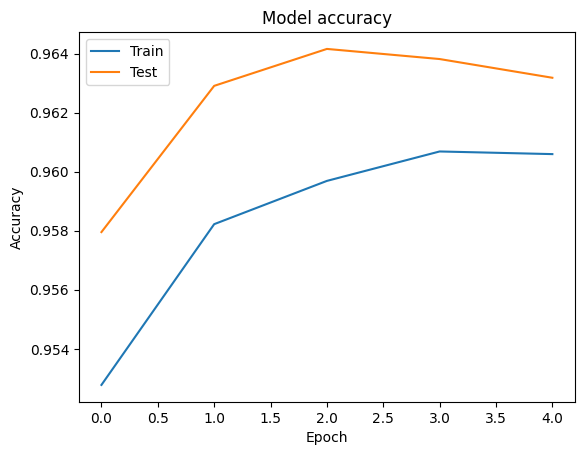

In [17]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

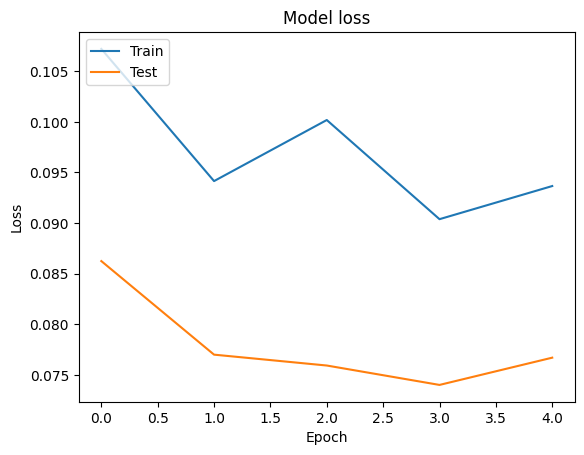

In [18]:
# Plot the training and validation loss over the epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()
# plt.savefig('los_plo.jpg')

In [19]:
y_pred = model.predict(np.expand_dims(X_test, axis=2))

In [20]:
y_pred_classes = np.argmax(y_pred, axis=1)

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    560180
        DDoS       0.93      0.98      0.96    114670
    Scanning       0.90      0.88      0.89     28558
   Injection       0.67      0.86      0.75     41155
        MITM       1.00      1.00      1.00       133
     Malware       0.99      0.47      0.64     33484

    accuracy                           0.96    778180
   macro avg       0.92      0.87      0.87    778180
weighted avg       0.97      0.96      0.96    778180



In [21]:
# Get detailed report as a dictionary
report_dict = classification_report(
    y_test,
    y_pred_classes,
    target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))],
    output_dict=True
)

# Convert to DataFrame and format with more floats
report_df = pd.DataFrame(report_dict).T  # transpose for better layout
report_df = report_df.round(4)  # round to 4 decimal places

print(report_df)

              precision  recall  f1-score      support
Normal           1.0000  1.0000    1.0000  560180.0000
DDoS             0.9301  0.9835    0.9561  114670.0000
Scanning         0.9005  0.8807    0.8905   28558.0000
Injection        0.6679  0.8585    0.7513   41155.0000
MITM             1.0000  1.0000    1.0000     133.0000
Malware          0.9920  0.4678    0.6358   33484.0000
accuracy         0.9628  0.9628    0.9628       0.9628
macro avg        0.9151  0.8651    0.8723  778180.0000
weighted avg     0.9681  0.9628    0.9607  778180.0000


In [22]:
# Binarize the true labels for multi-class AUC
y_test_bin = label_binarize(y_test, classes=list(attacks.values()))  # shape: (n_samples, n_classes)

# y_pred is already the softmax output: shape (n_samples, n_classes)
auc_macro = roc_auc_score(y_test_bin, y_pred, average='macro', multi_class='ovr')
auc_weighted = roc_auc_score(y_test_bin, y_pred, average='weighted', multi_class='ovr')

print(f"AUC (macro-averaged OvR): {auc_macro:.4f}")
print(f"AUC (weighted-averaged OvR): {auc_weighted:.4f}")

AUC (macro-averaged OvR): 0.9958
AUC (weighted-averaged OvR): 0.9987


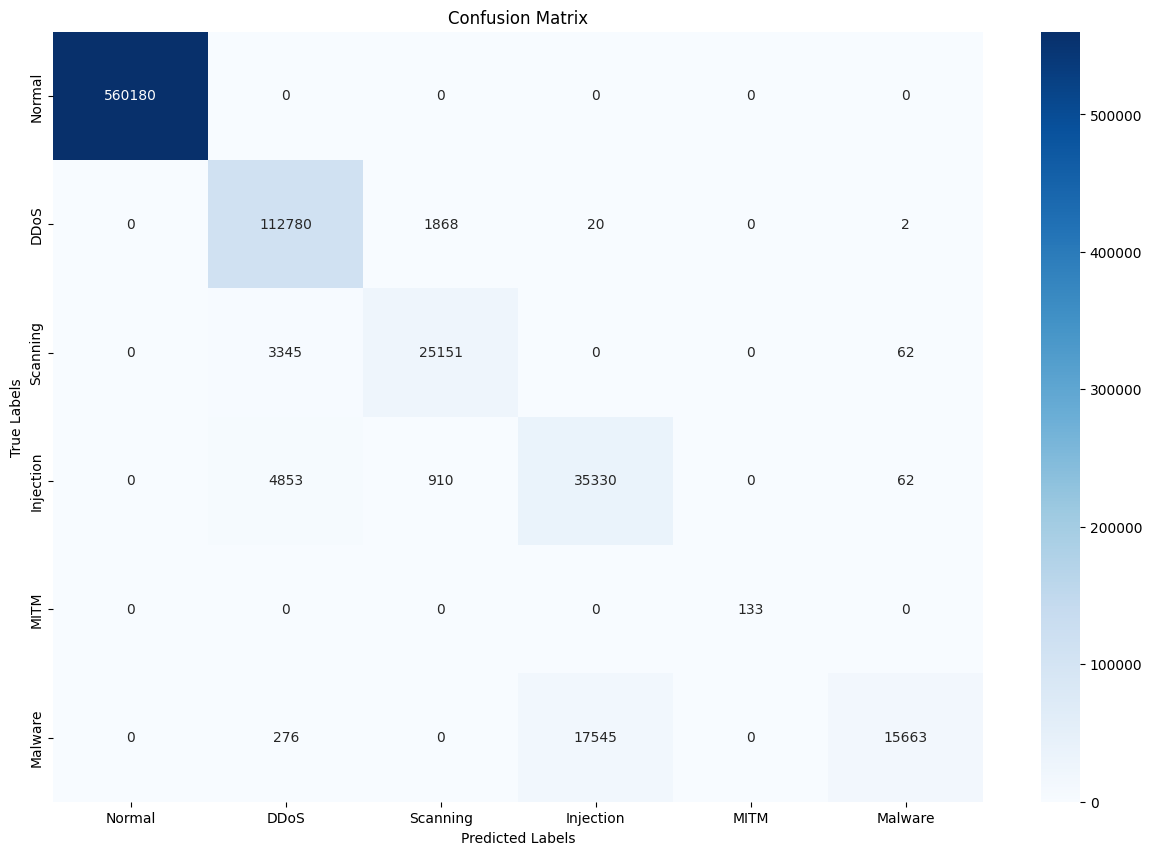

In [23]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
# plt.savefig('con_mat.jpg')

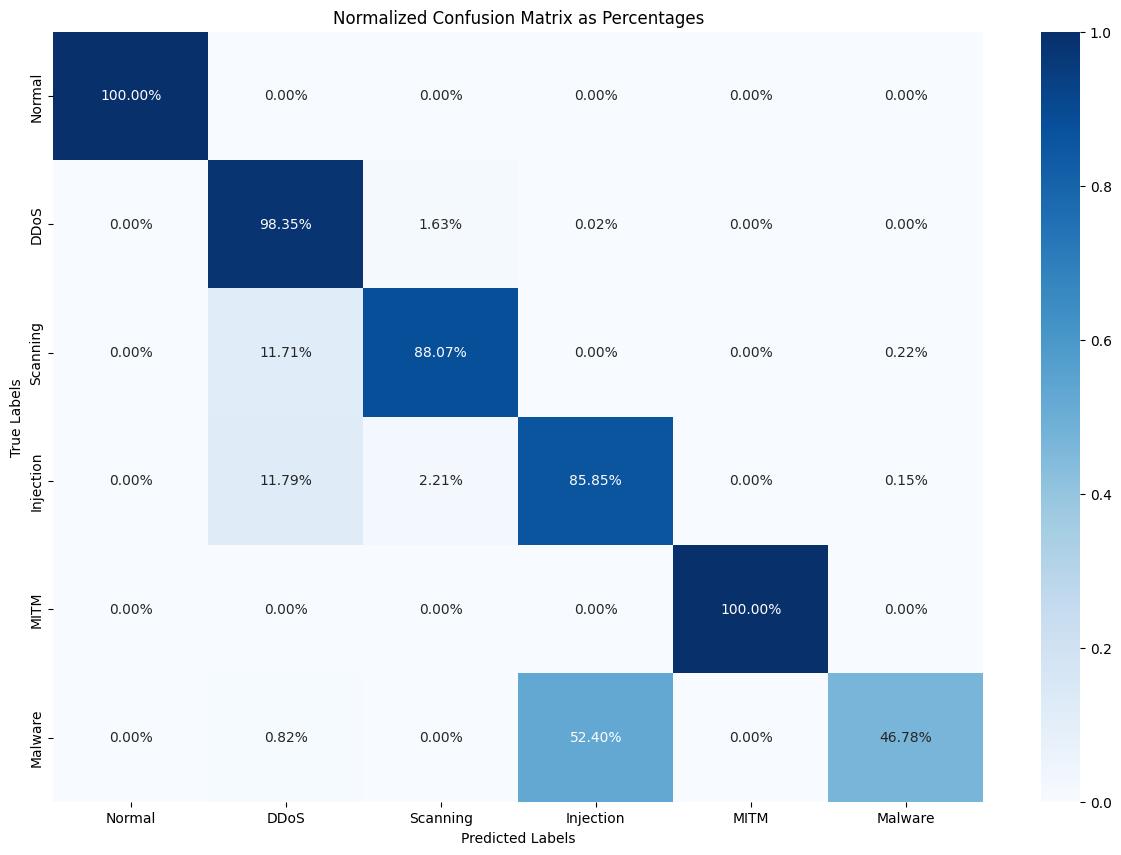

In [24]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')